# ¡Llena ese carrito!

## Diccionario de datos

Hay cinco tablas en el conjunto de datos, y tendrás que usarlas todas para hacer el preprocesamiento de datos y el análisis exploratorio de datos. A continuación se muestra un diccionario de datos que enumera las columnas de cada tabla y describe los datos que contienen.

- `instacart_orders.csv`: cada fila corresponde a un pedido en la aplicación Instacart.
    - `'order_id'`: número de ID que identifica de manera única cada pedido.
    - `'user_id'`: número de ID que identifica de manera única la cuenta de cada cliente.
    - `'order_number'`: el número de veces que este cliente ha hecho un pedido.
    - `'order_dow'`: día de la semana en que se hizo el pedido (0 si es domingo).
    - `'order_hour_of_day'`: hora del día en que se hizo el pedido.
    - `'days_since_prior_order'`: número de días transcurridos desde que este cliente hizo su pedido anterior.
- `products.csv`: cada fila corresponde a un producto único que pueden comprar los clientes.
    - `'product_id'`: número ID que identifica de manera única cada producto.
    - `'product_name'`: nombre del producto.
    - `'aisle_id'`: número ID que identifica de manera única cada categoría de pasillo de víveres.
    - `'department_id'`: número ID que identifica de manera única cada departamento de víveres.
- `order_products.csv`: cada fila corresponde a un artículo pedido en un pedido.
    - `'order_id'`: número de ID que identifica de manera única cada pedido.
    - `'product_id'`: número ID que identifica de manera única cada producto.
    - `'add_to_cart_order'`: el orden secuencial en el que se añadió cada artículo en el carrito.
    - `'reordered'`: 0 si el cliente nunca ha pedido este producto antes, 1 si lo ha pedido.
- `aisles.csv`
    - `'aisle_id'`: número ID que identifica de manera única cada categoría de pasillo de víveres.
    - `'aisle'`: nombre del pasillo.
- `departments.csv`
    - `'department_id'`: número ID que identifica de manera única cada departamento de víveres.
    - `'department'`: nombre del departamento.

# Paso 1. Descripción de los datos

## Plan de solución

Primero, inspeccionar el contenido crudo del archivo mediante open() y readline() para identificar el delimitador de los campos. Luego, utilizar este hallazgo al cargar los datos con pd.read_csv(), configurando el parámetro sep=';'. Finalmente, verificar la correcta ingestión de la información ejecutando el método .info(show_counts=True) para asegurar la integridad estructural.


In [1]:
import pandas as pd

In [2]:
with open('/datasets/instacart_orders.csv') as f:
    for i in range(5):
        print(f.readline())

order_id;user_id;order_number;order_dow;order_hour_of_day;days_since_prior_order

1515936;183418;11;6;13;30.0

1690866;163593;5;5;12;9.0

1454967;39980;4;5;19;2.0

1768857;82516;56;0;20;10.0



In [3]:
with open('/datasets/products.csv') as f:
    for i in range(5):
        print(f.readline())

product_id;product_name;aisle_id;department_id

1;Chocolate Sandwich Cookies;61;19

2;All-Seasons Salt;104;13

3;Robust Golden Unsweetened Oolong Tea;94;7

4;Smart Ones Classic Favorites Mini Rigatoni With Vodka Cream Sauce;38;1



In [4]:
with open('/datasets/aisles.csv') as f:
    for i in range(5):
        print(f.readline())

aisle_id;aisle

1;prepared soups salads

2;specialty cheeses

3;energy granola bars

4;instant foods



In [5]:
with open('/datasets/departments.csv') as f:
    for i in range(5):
        print(f.readline())

department_id;department

1;frozen

2;other

3;bakery

4;produce



In [6]:
with open('/datasets/order_products.csv') as f:
    for i in range(5):
        print(f.readline())

order_id;product_id;add_to_cart_order;reordered

2141543;11440;17.0;0

567889;1560;1.0;1

2261212;26683;1.0;1

491251;8670;35.0;1



In [7]:

df_instacart_orders= pd.read_csv('/datasets/instacart_orders.csv', sep=';')
print(df_instacart_orders.info(show_counts=True))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 478967 entries, 0 to 478966
Data columns (total 6 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   order_id                478967 non-null  int64  
 1   user_id                 478967 non-null  int64  
 2   order_number            478967 non-null  int64  
 3   order_dow               478967 non-null  int64  
 4   order_hour_of_day       478967 non-null  int64  
 5   days_since_prior_order  450148 non-null  float64
dtypes: float64(1), int64(5)
memory usage: 21.9 MB
None


In [8]:
df_products= pd.read_csv('/datasets/products.csv', sep=';')
print(df_products.info(show_counts=True))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49694 entries, 0 to 49693
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   product_id     49694 non-null  int64 
 1   product_name   48436 non-null  object
 2   aisle_id       49694 non-null  int64 
 3   department_id  49694 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 1.5+ MB
None


In [9]:

df_aisles= pd.read_csv('/datasets/aisles.csv', sep=';')
print(df_aisles.info(show_counts=True))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   aisle_id  134 non-null    int64 
 1   aisle     134 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.2+ KB
None


In [10]:
df_departments= pd.read_csv('/datasets/departments.csv', sep=';')
print(df_departments.info(show_counts=True))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   department_id  21 non-null     int64 
 1   department     21 non-null     object
dtypes: int64(1), object(1)
memory usage: 464.0+ bytes
None


In [11]:
df_order_products= pd.read_csv('/datasets/order_products.csv', sep=';')
print(df_order_products.info(show_counts=True))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4545007 entries, 0 to 4545006
Data columns (total 4 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   order_id           4545007 non-null  int64  
 1   product_id         4545007 non-null  int64  
 2   add_to_cart_order  4544171 non-null  float64
 3   reordered          4545007 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 138.7 MB
None


## Conclusiones

En todos los archivos, los puntos y comas (;) eran los separadores. Por ello, fue necesario usar sep=; al momento de leer los archivos con .info; al respecto, fue necesario usar el show_counts=True debido a la extensión del conjunto de los datos. Con show_counts=True me aseguré de obtener un mejor conteo de los valores no nulos. 
Sobre la lectura de los archivos, estás son mis conclusiones:

df_instacart_orders: 
La columna days_since_prior_order tiene menos valores no nulos en comparación con las demás columnas. Entiendo que days_since_prior_order  registra el número de días desde el pedido anterior, pero aquí podría haber valores nulos porque habrá quien apenas pidió su primer pedido, es decir, la columna  "order_number" solo tiene un registro. Si es el caso, no hay días previos qué registrar. Además, el tipo de valor es decimal.  

df_products:
En la columna "product_name" hay más valores ausentes en comparación con las otras columnas. Es una relación inusual porque significa que faltan los nombres del producto en una columna que debería tenerlos. Si bien, se podría obtener información la columna product_id, sería confuso que existiera un producto sin nombre registrado, lo que causa desafíos en la recolección de datos porque podría perderse la información del nombre del producto al carecer de una conexión clara con la columna product_name, que por cierto, tiene un tipo object.

df_aisles:
En esta caso ambas columnas tienen datos disponibles que podrían analizarse. Significa que no hay datos fantasma.

df_departments:
Ambas columnas tiene datos disponibles, podría facilitar el análisis, aunque la presencia de valores repetidos puede dificultar la comprensión del análisis.

df_order_products:
En add_to_cart_order hay un problema: faltan datos que serán importantes para analizar y podrían haberse perdido en el registro de los valores. Es importante porque permitiría saber cuáles son los productos que se seleccionan con mayor frecuencia.


<div class="alert alert-block alert-success">
</div>


# Paso 2. Preprocesamiento de los datos

## Plan de solución

Escribe aquí tu plan para el Paso 2. Preprocesamiento de los datos.
Primero, identificar y eliminar las filas idénticas y pares duplicados en la tabla orders aplicando drop_duplicates() y reseteando el índice. Luego, en products, inspeccionar duplicados de filas y de identificadores, analizar los nombres repetidos con distintos códigos, y rellenar los valores faltantes en product_name con una etiqueta genérica. Asimismo, en order_products, verificar la ausencia de duplicados completos y por combinación de campos, rellenar los valores faltantes en el orden de adición al carrito con una marca específica, y convertir dicha columna a tipo entero. Finalmente, validar que las tablas de departamentos y pasillos no presenten duplicados de filas, identificadores o nombres para garantizar la consistencia estructural de todo el pipeline.

In [12]:
duplicadas_instacart_orders = df_instacart_orders[df_instacart_orders.duplicated(keep=False)].sort_values('order_id')


print(duplicadas_instacart_orders.shape[0])
duplicadas_instacart_orders


30


,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
354993,391768,57671,19,3,2,10.0
371905,391768,57671,19,3,2,10.0
119251,408114,68324,4,3,2,18.0
321100,408114,68324,4,3,2,18.0
394347,467134,63189,21,3,2,2.0
250626,467134,63189,21,3,2,2.0
99462,794638,50898,24,3,2,2.0
145574,794638,50898,24,3,2,2.0
311713,1021560,53767,3,3,2,9.0
242618,1021560,53767,3,3,2,9.0


Hay 30 líneas duplicada y pueden observarse porque son identicas en todas las columnas, desde order_id hasta days_since_prior_order.

In [13]:


df_filtrado = df_instacart_orders[(df_instacart_orders['order_dow']==3) & (df_instacart_orders['order_hour_of_day']==2)]
print(df_filtrado)

df_dupicados_hora_dia= df_filtrado[df_filtrado.duplicated(keep=False)].sort_values('order_id')

print(df_dupicados_hora_dia.shape[0])
df_dupicados_hora_dia

        order_id  user_id  order_number  order_dow  order_hour_of_day  \
4838     2766110   162084            41          3                  2   
5156     2190225   138285            18          3                  2   
15506     553049    58599            13          3                  2   
18420     382357   120200            19          3                  2   
24691     690242    77357             2          3                  2   
...          ...      ...           ...        ...                ...   
457013   3384021    14881             6          3                  2   
458816    910166   164782            18          3                  2   
459635   1680532   106435             6          3                  2   
468324    222962    54979            59          3                  2   
477526   2592344    46860            38          3                  2   

        days_since_prior_order  
4838                      16.0  
5156                      11.0  
15506                   

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
354993,391768,57671,19,3,2,10.0
371905,391768,57671,19,3,2,10.0
119251,408114,68324,4,3,2,18.0
321100,408114,68324,4,3,2,18.0
394347,467134,63189,21,3,2,2.0
250626,467134,63189,21,3,2,2.0
99462,794638,50898,24,3,2,2.0
145574,794638,50898,24,3,2,2.0
311713,1021560,53767,3,3,2,9.0
242618,1021560,53767,3,3,2,9.0


¿Qué sugiere este resultado? Hay un error de registro porque la lista muestra datos duplicados tanto en el order id como el user id, algo que no debería pasar porque el order id es único. Además, la hora es inusual para los pedidos. Las 2 am. no es un horario de alta demanda. Podría tratarse de un error de registro del sistema debido a la hora en que ocurrió. Por úlitmo, es importante acaltar que los datos duplicados están en el dataset completo, no solo en el subjunto de miércoles a las 2 am. 

In [14]:
df_instacart_orders_noduplicado= df_instacart_orders.drop_duplicates().reset_index(drop=True)
print(df_instacart_orders_noduplicado)


        order_id  user_id  order_number  order_dow  order_hour_of_day  \
0        1515936   183418            11          6                 13   
1        1690866   163593             5          5                 12   
2        1454967    39980             4          5                 19   
3        1768857    82516            56          0                 20   
4        3007858   196724             2          4                 12   
...          ...      ...           ...        ...                ...   
478947   3210681     5617             5          1                 14   
478948   3270802   112087             2          3                 13   
478949    885349    82944            16          2                 11   
478950    216274     4391             3          3                  8   
478951   2071924     1730            18          1                 14   

        days_since_prior_order  
0                         30.0  
1                          9.0  
2                       

In [15]:
print(df_instacart_orders_noduplicado.duplicated().sum())


0


In [16]:
df_instacart_orders_noduplicado['order_id'].duplicated().value_counts()


False    478952
Name: order_id, dtype: int64

Encontré que se debían eliminar las filas duplicadas, pero conservando el índice countinuo luego de la eliminación, por eso usé .reset_index(drop=True) cuando descarté las filas iguales. De esa manera, se fueron 15 filas. 

### `products` data frame

In [17]:
# Verifica si hay filas totalmente duplicadas
duplicadas_en_products = df_products[df_products.duplicated(keep=False)].sort_values('product_id')

print(duplicadas_en_products.shape[0])
duplicadas_en_products


0


,product_id,product_name,aisle_id,department_id


In [18]:
duplicadas_idproducts = df_products[df_products['product_id'].duplicated(keep=False)].sort_values('product_id')

print(duplicadas_idproducts.shape[0])
duplicadas_idproducts



0


,product_id,product_name,aisle_id,department_id


In [19]:


df_productos_en_mayuscula = df_products['product_name'].str.upper()

duplicadas_en_mayuscula = df_productos_en_mayuscula[df_productos_en_mayuscula.duplicated(keep=False)].sort_values()

print(duplicadas_en_mayuscula.shape[0])
duplicadas_en_mayuscula


1465


23339    18-IN-1 HEMP PEPPERMINT PURE-CASTILE SOAP
31844    18-IN-1 HEMP PEPPERMINT PURE-CASTILE SOAP
19941              AGED BALSAMIC VINEGAR OF MODENA
13152              AGED BALSAMIC VINEGAR OF MODENA
24830           ALBACORE SOLID WHITE TUNA IN WATER
                           ...                    
49552                                          NaN
49574                                          NaN
49640                                          NaN
49663                                          NaN
49668                                          NaN
Name: product_name, Length: 1465, dtype: object

In [20]:
df_productos_mayusc = df_products['product_name'].str.upper()

df_productos_mayusc_sinnan = df_productos_mayusc.dropna()

df_productos_mayusc_duplicado= df_productos_mayusc_sinnan[df_productos_mayusc_sinnan.duplicated(keep=False)].sort_values()

print(df_productos_mayusc_duplicado.shape[0])
df_productos_mayusc_duplicado


207


23339    18-IN-1 HEMP PEPPERMINT PURE-CASTILE SOAP
31844    18-IN-1 HEMP PEPPERMINT PURE-CASTILE SOAP
19941              AGED BALSAMIC VINEGAR OF MODENA
13152              AGED BALSAMIC VINEGAR OF MODENA
24830           ALBACORE SOLID WHITE TUNA IN WATER
                           ...                    
46873                           VITAMIN D3 5000 IU
21366                WILD SARDINES IN SPRING WATER
40093                WILD SARDINES IN SPRING WATER
1826              YAMS CUT SWEET POTATOES IN SYRUP
38260             YAMS CUT SWEET POTATOES IN SYRUP
Name: product_name, Length: 207, dtype: object

In [21]:
#intento revisar si estas duplicaciones en los nombres tiene el mismo product_id para revisar si son productos duplicados:
index = df_productos_mayusc_duplicado.index

df_products['product_name_mayusc'] = df_products['product_name'].str.upper()

df_products_iloc = df_products.iloc[index]

df_repetidos_por_id = df_products_iloc.groupby('product_name_mayusc')['product_id'].unique()

print(df_repetidos_por_id)


product_name_mayusc
18-IN-1 HEMP PEPPERMINT PURE-CASTILE SOAP    [23340, 31845]
AGED BALSAMIC VINEGAR OF MODENA              [19942, 13153]
ALBACORE SOLID WHITE TUNA IN WATER           [24831, 22583]
AMERICAN CHEESE SLICES                          [9038, 516]
ANCHOVY FILLETS IN OLIVE OIL                 [49531, 12326]
                                                  ...      
VITAMIN D3 1000 IU                           [36536, 48749]
VITAMIN D3 2000 IU                            [4388, 16991]
VITAMIN D3 5000 IU                           [49443, 46874]
WILD SARDINES IN SPRING WATER                [21367, 40094]
YAMS CUT SWEET POTATOES IN SYRUP              [1827, 38261]
Name: product_id, Length: 103, dtype: object


Para este caso, consideré buena idea indigar respecto al id de los productos que se llaman igual en mayúsculas. Si bien, repiten el nombre, eso no significa que tengan el mismo código id de producto. Es probable que al momento de capturar los nombres solo se usaran mayúsculas por descuido. Identifiqué que existen 207 nombres repetidos pero asociados a distintos product_id. Tras evaluar estos casos, determiné que no se tratan de duplicados reales de datos, dado que cada registro posee un identificador único y las coincidencias en los textos corresponden a variaciones o descuidos en la captura original. Por lo tanto, decido conservar todos estos registros intactos en el catálogo, ya que representan entradas independientes y lógicamente válidas que no deben eliminarse mediante funciones de deduplicación.

### `departments` data frame

In [22]:
duplicados_departments = df_departments[df_departments.duplicated(keep=False)].sort_values(
'department_id')
print(duplicados_departments.shape[0])
duplicados_departments

0


,department_id,department


In [23]:
departments_en_minus= df_departments['department'].str.lower().str.strip()
duplicados_dep_str = df_departments[departments_en_minus.duplicated(keep=False)].sort_values('department_id')
print(duplicados_dep_str.shape[0])
duplicados_dep_str

0


,department_id,department


In [24]:
ids_dobles= df_departments[df_departments['department_id'].duplicated(keep=False)].sort_values(
'department_id')
print(ids_dobles.shape[0])
ids_dobles

0


,department_id,department


Describe brevemente tus hallazgos y lo que hiciste con ellos. Aquí no hubo filas duplicadas, de acuerdo a la búsqueda que hice con 'department_id', que representa número ID que identifica de manera única cada departamento de víveres. Es importante notarlo porque los datos están capturados sin repeticiones. 

### `aisles` data frame

In [25]:
duplicados_asiles= df_aisles[df_aisles.duplicated(keep=False)].sort_values('aisle_id')
print(duplicados_asiles.shape[0])
duplicados_asiles

0


,aisle_id,aisle


In [26]:

aisle_integrada= df_aisles['aisle'].str.lower().str.strip()
duplicadas_aisles_str = df_aisles[aisle_integrada.duplicated(keep=False)].sort_values('aisle_id')
print(duplicadas_aisles_str.shape[0])
duplicadas_aisles_str


0


,aisle_id,aisle


In [27]:
duplicadas_ids_asiles= df_aisles[df_aisles['aisle_id'].duplicated(keep=False)].sort_values('aisle_id')
print(duplicadas_ids_asiles.shape[0])
duplicadas_ids_asiles


0


,aisle_id,aisle


 Tampoco encontré duplicidades tanto en la columna aisle_id, como en la aisle, solo para confirmar que los datos no sean idénticos allí. Eso significa que los datos están en óptimas condiciones para hacer un análisis sin duplicados. 

### `order_products` data frame

In [28]:
duplicados_order_products= df_order_products[df_order_products.duplicated(keep=False)].sort_values('order_id')
print(duplicados_order_products.shape[0])
duplicados_order_products


0


,order_id,product_id,add_to_cart_order,reordered


In [29]:
duplicadas_idorder_idproducts= df_order_products[df_order_products.duplicated(subset=['order_id', 'product_id'], keep=False)].sort_values('order_id')
print(duplicadas_idorder_idproducts.shape[0])
duplicadas_idorder_idproducts


0


,order_id,product_id,add_to_cart_order,reordered




Primero busqué los valores duplicados en todo el conjunto de datos, obteniendo un resultado de 0. Sin embargo, dado que en la tabla order_products un mismo order_id se repite por cada producto que contiene el pedido y un mismo product_id aparece en múltiples pedidos de forma independiente, la verificación correcta requiere evaluar la combinación de ambos campos ('order_id' y 'product_id') como clave compuesta. Al buscar duplicados en dicha combinación, no encontré registros repetidos, lo que confirma que cada artículo está asociado una única vez a un pedido específico sin duplicaciones accidentales.

## Encuentra y elimina los valores ausentes

Al trabajar con valores duplicados, pudimos observar que también nos falta investigar valores ausentes:

* La columna `'product_name'` de la tabla products.
* La columna `'days_since_prior_order'` de la tabla orders.
* La columna `'add_to_cart_order'` de la tabla order_productos.

### `products` data frame

In [30]:
nulos_prodct_name= df_products[df_products[ 'product_name'].isna()]
nulos_prodct_name= nulos_prodct_name.sort_values('product_id')
print(nulos_prodct_name.shape[0])
nulos_prodct_name

1258


,product_id,product_name,aisle_id,department_id,product_name_mayusc
37,38,NaN,100,21,NaN
71,72,NaN,100,21,NaN
109,110,NaN,100,21,NaN
296,297,NaN,100,21,NaN
416,417,NaN,100,21,NaN
...,...,...,...,...,...
49552,49553,NaN,100,21,NaN
49574,49575,NaN,100,21,NaN
49640,49641,NaN,100,21,NaN
49663,49664,NaN,100,21,NaN


In [31]:
#quiero saber cómo qué sucede con aisle_id y department_id		
df_count_product_name = df_products[ 'product_name'].isna().sum() 
print(df_count_product_name)

df_count_aisle = (df_products['aisle_id']==100).sum()
print(df_count_aisle)

1258
1258




Los nombres ausentes en 1258 filas, corresponden con un el aisle_id=100 y con department_id=21. Parece que hay una especie de espacio ahí para los productos sin catalogar. 


In [32]:
nulos_prodct_name= df_products[df_products[ 'product_name'].isna()]

print(nulos_prodct_name.shape[0])

aisle_null= nulos_prodct_name[nulos_prodct_name['aisle_id']==100]

print(aisle_null.shape[0])


1258
1258


Los nombres de productos ausentes están relacionados con el pasillo con ID 100 porque coinciden en el número de filas vacías. Hay productos sin catalogar con un nombre , pero son almacenados en un pasillo específico

In [33]:

nulos_prodct_name= df_products[df_products['product_name'].isna()]

print(nulos_prodct_name.shape[0])

departamento_null= nulos_prodct_name[nulos_prodct_name['department_id']==21]

print(departamento_null.shape[0])



1258
1258



Dado que el número de filas también coincide en este caso, los productos sin nombre están en una zona especial (aisle_id == 100 y department_id == 21) donde comparten departamento y pasillo. Aunque esto no es necesariamente una mala práctica, es importante asignar un valor para incluirlos en cualquier tipo de análisis, como "nombre_no_ asignado".

In [34]:
aisles_null = df_aisles[df_aisles['aisle_id']==100]

print(aisles_null)

departamentos_null = df_departments[df_departments['department_id']==21]

print(departamentos_null)


    aisle_id    aisle
99       100  missing
    department_id department
20             21    missing



Al investigar lo que sucede en estas tablas se confirma que hay datos con catalogados como "missing". El aisle correspondiente al aisle_id 100 es "missing". El department es también "missing" para el department_id 21. Además, esto se relaciona con la falta de valores para los nombres de los productos, es decir, 1258 filas que tenían aisle_id == 100 y department_id == 21.

In [35]:

df_products['product_name']=df_products['product_name'].fillna('Unknown')

nombres_unknown_fill= df_products[df_products['product_name']==('Unknown')]

print(nombres_unknown_fill)
print(df_products['product_name'].isna().sum())


       product_id product_name  aisle_id  department_id product_name_mayusc
37             38      Unknown       100             21                 NaN
71             72      Unknown       100             21                 NaN
109           110      Unknown       100             21                 NaN
296           297      Unknown       100             21                 NaN
416           417      Unknown       100             21                 NaN
...           ...          ...       ...            ...                 ...
49552       49553      Unknown       100             21                 NaN
49574       49575      Unknown       100             21                 NaN
49640       49641      Unknown       100             21                 NaN
49663       49664      Unknown       100             21                 NaN
49668       49669      Unknown       100             21                 NaN

[1258 rows x 5 columns]
0


### `orders` data frame

In [36]:

nulos_orders= df_instacart_orders_noduplicado[df_instacart_orders_noduplicado['days_since_prior_order'].isna()]
nulos_orders= nulos_orders.sort_values('order_number')
print(nulos_orders.shape[0])
nulos_orders


28817


,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
28,133707,182261,1,3,10,NaN
320420,2573704,92897,1,3,9,NaN
320406,1411305,169247,1,0,8,NaN
320384,2300293,32810,1,0,13,NaN
320382,228858,107288,1,5,10,NaN
...,...,...,...,...,...,...
160309,1801395,116168,1,1,7,NaN
160284,1253128,198314,1,3,14,NaN
160275,1027108,138219,1,0,13,NaN
159667,402920,57451,1,5,0,NaN


In [37]:
si_reorder_filtro= nulos_orders[nulos_orders['order_number'] ==1]

print(si_reorder_filtro.shape[0])
print (nulos_orders.shape[0]-si_reorder_filtro.shape[0])
si_reorder_filtro


28817
0


,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
28,133707,182261,1,3,10,NaN
320420,2573704,92897,1,3,9,NaN
320406,1411305,169247,1,0,8,NaN
320384,2300293,32810,1,0,13,NaN
320382,228858,107288,1,5,10,NaN
...,...,...,...,...,...,...
160309,1801395,116168,1,1,7,NaN
160284,1253128,198314,1,3,14,NaN
160275,1027108,138219,1,0,13,NaN
159667,402920,57451,1,5,0,NaN


Al analizar la tabla orders, determiné que los valores nulos en la columna days_since_prior_order corresponden solo a los registros donde el order_number es igual a 1. Esta correspondencia exacta (verificada al comprobar que la diferencia entre el total de valores faltantes y el subgrupo de primeros pedidos es de cero) confirma que dichos campos vacíos ocurren de manera lógica en el primer pedido de cada cliente, dado que al tratarse de su ingreso inicial al sistema, no existe un pedido previo con el cual calcular el tiempo transcurrido.

### `order_products` data frame

In [38]:
null_order_products= df_order_products[df_order_products.isna().any(axis=1)]
print(null_order_products.shape[0])
null_order_products

836


,order_id,product_id,add_to_cart_order,reordered
737,2449164,5068,NaN,0
9926,1968313,43867,NaN,0
14394,2926893,11688,NaN,0
16418,1717990,4142,NaN,0
30114,1959075,42828,NaN,1
...,...,...,...,...
4505662,1800005,7411,NaN,0
4511400,1633337,260,NaN,0
4517562,404157,9517,NaN,0
4534112,1673227,17835,NaN,0


In [39]:
print(df_order_products['add_to_cart_order'].min())

print(df_order_products['add_to_cart_order'].max())


1.0
64.0



El 1.0 representa el primer producto agregado. Todo pedido debe tener al menos un producto para existir, por lo que la secuencia siempre iniciará en uno.
El valor máximo es 64.0: Esto nos indica que el pedido más grande registrado en este conjunto de datos contiene 64 artículos distintos.

In [40]:
nulos_idorder= df_order_products['add_to_cart_order'].isna()
vacios_idorder_addcart= df_order_products[nulos_idorder]['order_id']
print(vacios_idorder_addcart.shape[ 0])
vacios_idorder_addcart

836


737        2449164
9926       1968313
14394      2926893
16418      1717990
30114      1959075
            ...   
4505662    1800005
4511400    1633337
4517562     404157
4534112    1673227
4535739    1832957
Name: order_id, Length: 836, dtype: int64

In [41]:

group_orderid_cuenta= df_order_products[df_order_products['order_id'].isin(vacios_idorder_addcart)].groupby('order_id')['product_id'].size().reset_index(inplace=False)
print('El valor mínimo del conteo para product_id es:', group_orderid_cuenta[ 'product_id'].min())
group_orderid_cuenta

El valor mínimo del conteo para product_id es: 65


,order_id,product_id
0,9310,65
1,61355,127
2,102236,95
3,129627,69
4,165801,70
...,...,...
65,2999801,70
66,3125735,86
67,3308010,115
68,3347453,71



Sí, todos los pedidos con valores ausentes tienen más de 64 productos. Esto se comprueba porque, al calcular el mínimo de productos por pedido en el grupo de valores ausentes, el resultado fue 65. Los valores ausentes están relacionados a pedidos grandes, por ejemplo, desde 65 productos.

In [42]:
df_order_products['add_to_cart_order']= df_order_products['add_to_cart_order'].fillna(999)
df_order_products['add_to_cart_order'] = df_order_products['add_to_cart_order'].astype(int)
print(df_order_products['add_to_cart_order'].isna().sum())
print(df_order_products['add_to_cart_order'].dtype)


0
int64




Encontré que los datos ausentes de la columna add_to_cart_order estaban ausentes y necesitaban ser reemplazados con algún tipo de valor númerico, en este caso 999. Con esto puedo realizar un mejor análisis de los datos. Además, la columna ni siquiera tenía un tipo aceptable para el análisis, por lo que tuve que comvertirla al tipo entero. 


## Conclusiones

Escribe aquí tus conclusiones intermedias sobre el Paso 2. Preprocesamiento de los datos:
Hubo muchos pasos a realizar para preparar los datos. Desde el inicio, empleé with open para observar cómo se separaban los datos en cada lista. En cuanto a valores ausentes, con tipos diferentes, la relación de los pedidos y el orden de productos agregados al carrito, hay relaciones con el tamaño de los pedidos.
Lo primero que noté fue un error de registro. Encontré 15 filas duplicadas con el mismo número de orden y de usuario, algo que lógicamente no debería pasar porque cada orden es única. Curiosamente, esto sucedió a las 2 de la mañana, un horario de muy baja demanda. Esto me hace pensar que más bien fue un fallo técnico del sistema al procesar los datos durante la madrugada y no un comportamiento real de los clientes. Eliminé estas filas, reacomodé el índice para que quedara continuo y me aseguré de que ya no hubiera ningún otro dato repetido en los identificadores de productos o departamentos. 

Tratamiento de datos ausentes

Después, me encontré con 1,258 filas que no tenían nombre de producto. Al principio parecía información incompleta, pero al investigar a fondo vi que todos estos casos caían en el pasillo 100 y en el departamento 21, los cuales están catalogados en el sistema como "missing". Esto significa que la base de datos tiene un espacio asignado para el inventario sin catalogar. 

Tamaño de los pedidos y sus límites

Otro hallazgo muy interesante tiene que ver con el límite del sistema respecto al tamaño de los pedidos. Al revisar el orden en que se agregan las cosas al carrito, vi que el contador empieza en 1, pero se detiene en 64 artículos. Lo revelador fue descubrir que todos los valores ausentes en esta sección correspondían a pedidos de 65 productos o más. Para solucionar esto y poder hacer un buen análisis  , convertí la columna a números enteros y rellené esos vacíos con un 999. De esta manera, sé  que se trata de una compra masiva.

Comportamiento de consumo.
Finalmente, quise entender un poco más sobre estos registros atípicos. Al cruzar los datos, descubrí que 517 de esos casos correspondían a la primera vez que un cliente pedía un artículo, mientras que otros 319 fueron de productos que la persona ya había ordenado antes. Esto demuestra que el fenómeno de los carritos masivos o valores ausentes ocurre tanto en los primeros pedidos como en la recompra.

# Paso 3. Análisis de los datos



### [A1] Verifica que los valores sean sensibles

In [43]:
print( 'El valor mínimo para order_hour_of_day es:', df_instacart_orders[ 'order_hour_of_day'].min()) 
print('El valor máximo para order_hour_of_day es:' ,df_instacart_orders[ 'order_hour_of_day'].max())

El valor mínimo para order_hour_of_day es: 0
El valor máximo para order_hour_of_day es: 23


In [44]:
print('El valor mínimo para order_dow es:', df_instacart_orders[ 'order_dow'].min())
print('El valor máximo para order_dow es:' ,df_instacart_orders[ 'order_dow'].max())

El valor mínimo para order_dow es: 0
El valor máximo para order_dow es: 6



Los datos son coherentes porque para order_hour_of_day van de 0 a 23 horas y para order_dow van de 0 a 6, que representa los días de la semana. Si hubiera observado un -1 o un 24 en order_hour_of_day, habría un problema debido a la forma en que se trabaja en este programa. Usualmente, las cuentas para índices comienzan desde 0. La misma situación aplicaría en caso de obtener un -1 y un 7 en order_dow. Para ambas columnas, los escenarios anteriores no se presentaron, entonces significa que todo está en orden.


### [A2] Para cada hora del día, ¿cuántas personas hacen órdenes?

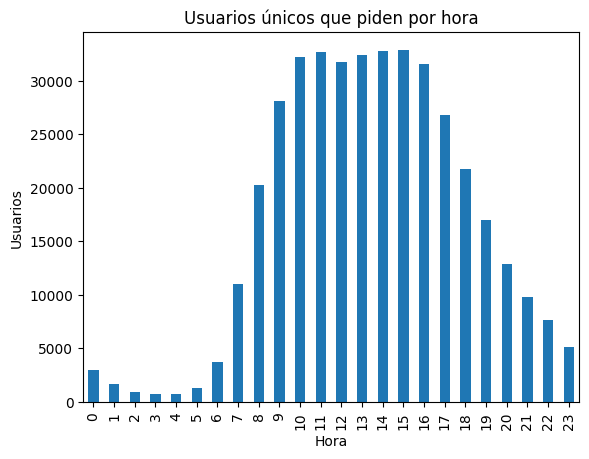

In [45]:
import matplotlib.pyplot as plt

df_instacart_orders_noduplicado.groupby('order_hour_of_day')['user_id'].nunique()

df_instacart_orders_noduplicado.groupby('order_hour_of_day')['user_id'].nunique().sort_index().plot(kind='bar')
plt.xlabel('Hora')
plt.ylabel('Usuarios')
plt.title('Usuarios únicos que piden por hora')
plt.show()


De acuerdo con la exploración de datos y la representación de la gráfica, el periodo inactivo, donde hay pocos pedidos (apenas 5000) es de 0 a 6 horas. Después tenemos un crecimiento en la cantidad de pedidos desde las 7 horas y llega a su punto más alto a las 10 horas, donde se registran más de 40000 pedidos. Los números de la cantidad de pedidos se mantienen altos desde las 10 a las 16 horas, pero la caída llega desde las 17 a 18 horas con más de 30000 pedidos, sin llegar a la marca de los 35000 pedidos. Desde las 17 horas hay un descenso sostenido hasta las 23 horas, donde apanas se superan los 5000 pedidos.

### [A3] ¿Qué día de la semana compran víveres las personas?

0    84090
1    82185
2    65833
3    60897
4    59810
5    63488
6    62649
Name: order_dow, dtype: int64


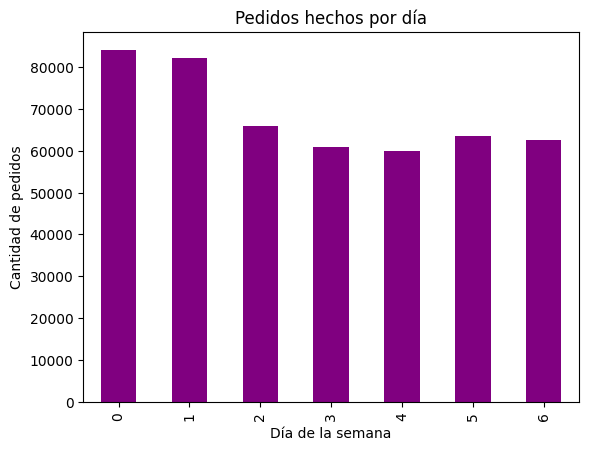

In [46]:
import matplotlib.pyplot as plt

print(df_instacart_orders_noduplicado['order_dow'].value_counts().sort_index())

df_instacart_orders_noduplicado['order_dow'].value_counts().sort_index().plot(kind='bar', color='purple')

plt.xlabel('Día de la semana')
plt.ylabel('Cantidad de pedidos')
plt.title('Pedidos hechos por día')
plt.show()


 
De acuerdo con la gráfica y la exploración de los datos, el domingo (día de la semana 0) es el día con más pedidos. Supera los 80000. El número es muy similar al lunes (día de la semana 1), pero desde ese día y el martes hay un descenso abrupto, donde el martes (día de la semana 2) registra más de 60000 pedidos. La tendencia continúa hasta llegar al punto más bajo el jueves (día de la semana 4), cuando los pedidos se mantienen por debajo de 60000. Por último, hay una recuperación el viernes (día de la semana 5) y el sábado (día de la semana 6). En ambos días, los pedidos apenas superan los 60000.


### [A4] ¿Cuánto tiempo esperan las personas hasta hacer otro pedido? Comenta sobre los valores mínimos y máximos.

El valor mínimo para days_since_prior_order: 0.0
El valor máximo para days_since_prior_order: 30.0


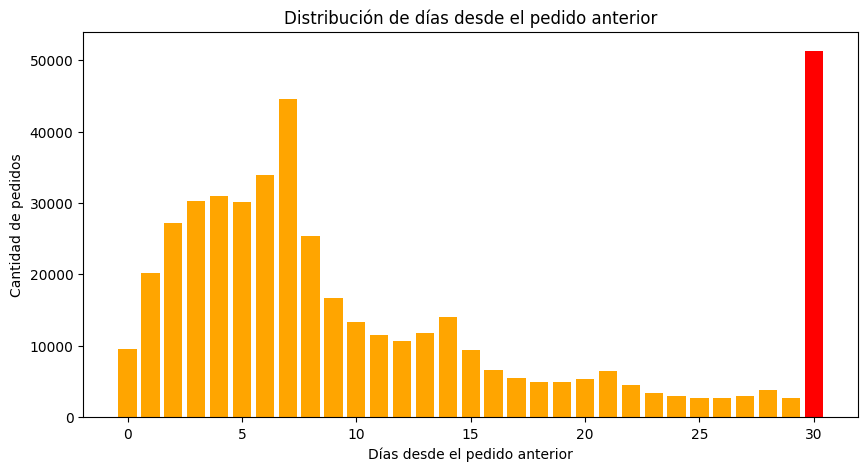

In [47]:
import matplotlib.pyplot as plt

print( 'El valor mínimo para days_since_prior_order:',df_instacart_orders_noduplicado[ 'days_since_prior_order'].min()) 
print('El valor máximo para days_since_prior_order:' ,df_instacart_orders_noduplicado[ 'days_since_prior_order'].max())

df_instacart_orders_noduplicado[ 'days_since_prior_order'].value_counts()
instacart_orderso_ordenado=df_instacart_orders_noduplicado[ 'days_since_prior_order'].value_counts().sort_index()

colores = ["orange"] * 30 + ["red"] * 1

plt.figure(figsize=(10, 5))
plt.bar(instacart_orderso_ordenado.index, instacart_orderso_ordenado.values, color=colores)
plt.xlabel('Días desde el pedido anterior')
plt.ylabel('Cantidad de pedidos')
plt.title('Distribución de días desde el pedido anterior')
plt.show()



Al revisar la gráfica, queda clarísimo cuándo compra la gente: el pico más alto no es un rango al azar, sino exactamente a la semana de su último pedido (entre los días 6 y 9). Esto tiene todo el sentido, porque solemos hacer el súper cada 7 días, justo cuando se nos acaba lo básico o tenemos tiempo libre. Pasando esa primera semana, las compras caen a la mitad y entramos en una racha muy floja entre los 15 y 25 días. Por último, ese salto repentino a los 30 días no significa que todos regresen a comprar mágicamente al mes exacto; más bien, es un tope artificial del sistema que mete en un mismo costal a todos los clientes que tardaron 30 días o más en volver. La barra de 30, en color rojo, rompe el patrón de compra que iba a la baja (menos de 10000). Es sospechoso que esto suceda.

### [B1] Diferencia entre miércoles y sábados para  `'order_hour_of_day'`.

15    5163
10    5026
11    5004
16    4976
14    4774
12    4688
13    4674
9     4490
17    4175
18    3463
8     3125
19    2652
20    1917
7     1732
21    1450
22    1154
23     718
6      643
0      373
1      215
5      170
4      108
2      106
3      101
Name: order_hour_of_day, dtype: int64


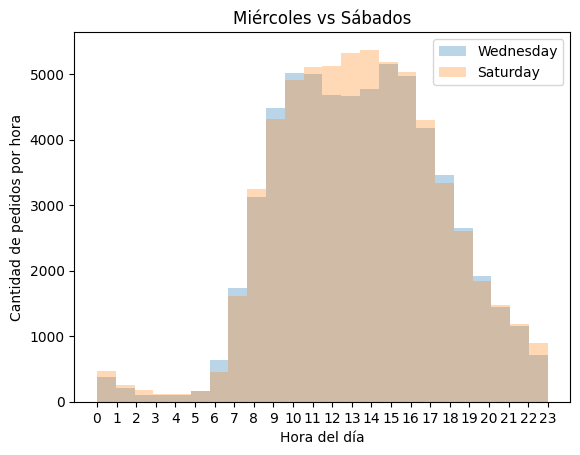

In [48]:


import matplotlib.pyplot as plt

fil_miercoles= df_instacart_orders_noduplicado[df_instacart_orders_noduplicado['order_dow'] == 3]
print(fil_miercoles['order_hour_of_day'].value_counts())

sabado_fil= df_instacart_orders_noduplicado[df_instacart_orders_noduplicado['order_dow'] == 6]

plt.hist(fil_miercoles['order_hour_of_day'],  bins=24, alpha=0.3, label='Wednesday')
plt.hist(sabado_fil['order_hour_of_day'],   bins=24, alpha=0.3, label='Saturday')

plt.xlabel( 'Hora del día')
plt.ylabel('Cantidad de pedidos por hora')
plt.title('Miércoles vs Sábados')
plt.legend()
plt.xticks(range(0,24))
plt.show()


Usé plt.xlim(0, 24) para cuidar el espacio entre las barras y dar un espacio al final para los pedidos que se realizaron a lo largo de las 23 horas. Lo hice para mantener 24 intervalos que son las horas de un día. Debido a esto, observo que el ritmo de compras es casi idéntico los miércoles y los sábados: durante la madrugada (de 0 a 5) casi no hay movimiento, a las 8 a.m. los pedidos se disparan y la hora pico se mantiene activa entre las 10:00 y las 15:00. La única diferencia sutil es que los sábados tienen un volumen ligeramente mayor a media tarde (15 horas) frente a los miércoles, pero en general, la rutina de compra a lo largo del día no cambia drásticamente.

### [B2] ¿Cuál es la distribución para el número de pedidos por cliente?

1
28


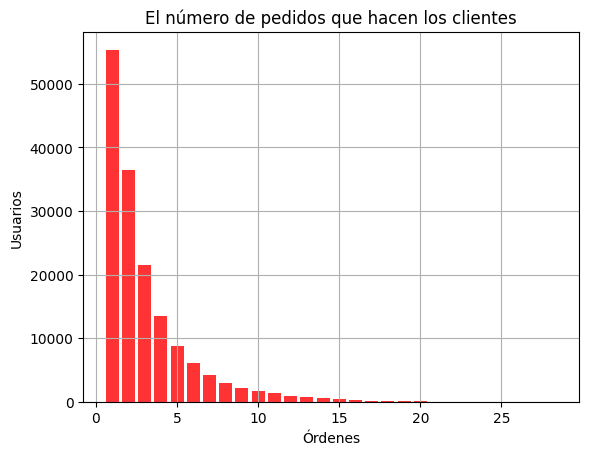

In [49]:
ordenes_por_usuario= df_instacart_orders_noduplicado.groupby('user_id')['order_id'].nunique().reset_index(inplace=False)
print(ordenes_por_usuario['order_id'].min())
print(ordenes_por_usuario['order_id'].max())
ordenes_por_usuario['order_id'].hist(bins=[x + 0.5 for x in range(29) ], rwidth= 0.8, color= 'red', alpha=0.8)

plt.xlabel( 'Órdenes')
plt.ylabel('Usuarios')
plt.title('El número de pedidos que hacen los clientes')

plt.show()

Usé bins=[x + 0.5 for x in range(29)  para alinear mejor cada barra de acuerdo a los valores de x y dejar un poco de espacio entre columnas.  Al observar la distribución de los datos, es evidente que está fuertemente sesgada hacia un extremo, ya que la gran mayoría de las personas realiza muy pocos pedidos. La mayor concentración se encuentra en el rango de 1 a 5 pedidos, un bloque que por sí solo supera los 50,000 usuarios. Esto nos revela un patrón de consumo muy claro: la plataforma atrae a un volumen masivo de clientes esporádicos, mientras que los usuarios que realizan compras de forma muy frecuente o en grandes cantidades representan una minoría.

### [B3] ¿Cuáles son los 20 productos más populares (muestra su ID y nombre)?

In [50]:
df_count_orders= df_order_products['product_id'].value_counts().to_frame().reset_index() 

df_unida =df_count_orders.merge(df_products, on='product_id', how='left')

df_unida = df_unida.dropna(subset=['product_name'])

print(df_unida[['product_id','product_name']].head(21))


    product_id                                       product_name
2        37039                                    Shiraz Cabernet
3        33971                                      Sliders Rolls
4        29773                                            Unknown
5        24689         With Olive Oil Squeeze Mayonnaise Dressing
6        21495                        Extra Extra Dry Ultra Fresh
7        20018                                        Cheese Buns
8        19690                                  Green Oak Lettuce
9        19600   Classic Meal for 2 Chicken Florentine & Farfalle
10       19197            Show Me the Honey Crunchy Coconut Chips
11       15898  Mango Peach Omega Swirl Omage-3 Fish Oil Suppl...
12       15292                           Made Vitamin D3 1000 I.U
13       14584  Chewy Chocolate Made with Reese's Peanut Butte...
14       13879                      Organic Green Tea with Ginger
15       13675                        Pure Tart Cherry 100% Juice
16       1

In [51]:
print(df_products[df_products['product_id']==66050])

Empty DataFrame
Columns: [product_id, product_name, aisle_id, department_id, product_name_mayusc]
Index: []


In [52]:
print(df_products[df_products['product_id']==53297])

Empty DataFrame
Columns: [product_id, product_name, aisle_id, department_id, product_name_mayusc]
Index: []


En el análisis identifiqué un problema de consistencia referencial en los datos originales: el product_id 66050 y 53297 registran ventas en la tabla de pedidos (df_order_products), pero no existe en el catálogo general (df_products). Esto provocó que, al fusionar la información, el nombre del producto apareciera como nulo (NaN). Intenté rastrear el problema con un filtrado para encontrar qué información hay disponibles sobre estos ids, pero el resultado para ambos casos fue: empty DataFrame. Por ello, decidí eliminarlos. Este hallazgo revela una falla de registro cruzado en el sistema de la tienda: permitio procesar y registrar la compra de un artículo que nunca fue dado de alta formalmente en la base de datos del inventario.

### [C1] ¿Cuántos artículos compran normalmente las personas en un pedido? ¿Cómo es la distribución?

In [53]:
df_order_products.groupby('order_id')['product_id'].count().max()

127

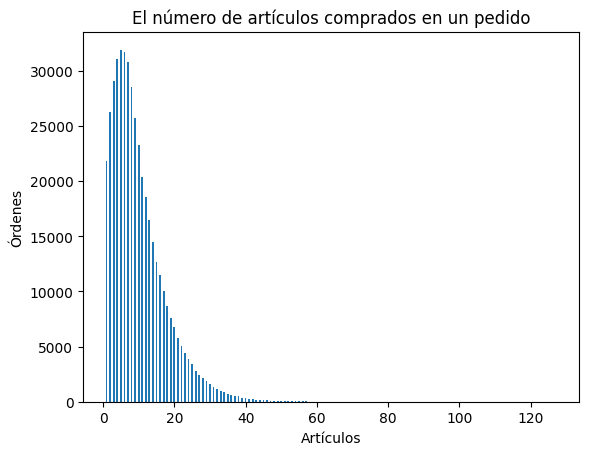

In [54]:
df_order_products.groupby('order_id')[ 'product_id'].count().plot(kind='hist', bins=[x + 0.5 for x in range(128)], rwidth=0.5)
plt.xlabel( 'Artículos')
plt.ylabel('Órdenes')
plt.title('El número de artículos comprados en un pedido')

plt.show()


La cantidad principal de los datos se agrupa en compras de tamaño reducido,  que abarca de 1 a 10 artículos. El pico de la gráfica ocurre entre los 4 y 7 productos por carrito, superando las 30000 órdenes. Esta concentración crea un sesgo hacia la derecha. La información se acumula en el extremo izquierdo y forma una cola descendente hacia los números mayores. Por esta razón, los carritos que superan los 60 artículos representan casos raros. Desde los 40 productos las barras dejan de ser visibles, un detalle que clasifica las compras masivas como excepciones en el registro general.

### [C2] ¿Cuáles son los 20 principales artículos que vuelven a pedirse con mayor frecuencia?

In [55]:
df_reordered = df_order_products[df_order_products['reordered'] == 1]

df_count = df_reordered.groupby('product_id')['reordered'].count().reset_index(inplace=False) 

df_count=df_count.rename(columns={'reordered': 'times_reordered'}) 

df_add = df_products.merge(df_count, on='product_id') 

df_top_20 = df_add.sort_values(by= 'times_reordered', ascending=False)[['product_name', 'product_id']] 

print(df_top_20.head(20))

                   product_name  product_id
18104                    Banana       24852
9528     Bag of Organic Bananas       13176
15368      Organic Strawberries       21137
15936      Organic Baby Spinach       21903
34407      Organic Hass Avocado       47209
34828           Organic Avocado       47766
20285        Organic Whole Milk       27845
34725               Large Lemon       47626
20375       Organic Raspberries       27966
12193              Strawberries       16797
19088                     Limes       26209
16700      Organic Yellow Onion       22935
18186            Organic Garlic       24964
32792          Organic Zucchini       45007
36219            Cucumber Kirby       49683
20543        Organic Fuji Apple       28204
5978   Apple Honeycrisp Organic        8277
28607       Organic Blueberries       39275
4267              Organic Lemon        5876
35905       Organic Half & Half       49235



Los 20 artículos con mayor volumen de recompra incluyen plátanos, fresas, espinacas, aguacates, leche, limones, frambuesas, cebollas, ajo, calabacines, pepinos, manzanas, arándanos y crema. Esto marca una clara tendencia por opciones orgánicas. Las frutas, verduras y lácteos frescos poseen una vida útil corta, lo que orilla a las familias a reabastecer sus despensas en ciclos breves. Las mercancías empaquetadas o productos de limpieza mantienen fechas de caducidad extensas, reduciendo la necesidad de adquisiciones repetidas.

### [C3] Para cada producto, ¿cuál es la proporción de las veces que se pide y que se vuelve a pedir?

In [56]:
df_pagrup = df_order_products.groupby('product_id')['order_id'].count().reset_index(inplace=False) 


df_again = df_order_products[df_order_products['reordered'] == 1].groupby('product_id')['reordered'].count().reset_index(inplace=False) 


df_join = df_pagrup.merge(df_again, on='product_id', how='left') 


df_join['reordered']= df_join['reordered'].fillna(0) 


df_proportion = df_join.merge(df_products, on='product_id', how='left') 

df_proportion['reorder_proportion']= df_proportion['reordered']/df_proportion['order_id'] 


df_proportion['reorder_percentage']= df_proportion['reorder_proportion']*100


print(df_proportion[['product_id', 'product_name','reorder_percentage']]) 




       product_id                                       product_name  \
0               1                         Chocolate Sandwich Cookies   
1               2                                   All-Seasons Salt   
2               3               Robust Golden Unsweetened Oolong Tea   
3               4  Smart Ones Classic Favorites Mini Rigatoni Wit...   
4               7                     Pure Coconut Water With Orange   
...           ...                                                ...   
45568       49690                      HIGH PERFORMANCE ENERGY DRINK   
45569       49691                      ORIGINAL PANCAKE & WAFFLE MIX   
45570       49692    ORGANIC INSTANT OATMEAL LIGHT MAPLE BROWN SUGAR   
45571       49693                             SPRING WATER BODY WASH   
45572       49694                            BURRITO- STEAK & CHEESE   

       reorder_percentage  
0               56.428571  
1                0.000000  
2               73.809524  
3               51.0204

In [57]:
df_products['product_id'].nunique()

49694

In [58]:
df_proportion[df_proportion['product_id'] == 2]

,product_id,order_id,reordered,product_name,aisle_id,department_id,product_name_mayusc,reorder_proportion,reorder_percentage
1,2,11,0.0,All-Seasons Salt,104,13,ALL-SEASONS SALT,0.0,0.0



El uso de la función nunique representó una medida cautelar para revisar la cantidad de valores únicos, descartando duplicados en la columna. Al analizar la tabla, los porcentajes de recompra elevados pertenecen a bebidas de consumo rutinario, ejemplificadas por el té o la bebida energética, con cifras superiores al setenta por ciento. En contraste, los niveles nulos corresponden a artículos de despensa con vida útil extensa, destacando el producto All-Seasons Salt con un cero por ciento. Los registros de este artículo muestran once pedidos en su totalidad, pero una suma de cero en la categoría de reorden, señalando compras de primera vez sin un retorno de los clientes. El patrón señala una rutina de consumo predecible: las personas reponen líquidos y alimentos perecederos en ciclos cortos, y adquieren condimentos o bienes duraderos en ocasiones contadas.

### [C4] Para cada cliente, ¿qué proporción de sus productos ya los había pedido?

In [59]:

df_mer_order_insta= df_instacart_orders_noduplicado.merge(df_order_products, on='order_id') 

df_client= df_mer_order_insta.groupby('user_id')['product_id'].count().reset_index(inplace=False)

df_client=df_client.rename(columns={'product_id': 'total_products'})

df_reoders_user= df_mer_order_insta[df_mer_order_insta['reordered'] == 1].groupby('user_id')['reordered'].count().reset_index(inplace=False) 

df_client_reorder= df_client.merge(df_reoders_user, on='user_id', how='left')

df_client_reorder['reordered']= df_client_reorder['reordered'].fillna(0) 

df_client_reorder['reorder_proportion']= df_client_reorder['reordered']/df_client_reorder['total_products'] 

df_client_reorder['reorder_percentage']= df_client_reorder['reorder_proportion']*100

print(df_client_reorder[['user_id', 'reorder_proportion','reorder_percentage']])
df_client_reorder.head()


        user_id  reorder_proportion  reorder_percentage
0             2            0.038462            3.846154
1             4            0.000000            0.000000
2             5            0.666667           66.666667
3             6            0.000000            0.000000
4             7            0.928571           92.857143
...         ...                 ...                 ...
149621   206203            0.222222           22.222222
149622   206206            0.714286           71.428571
149623   206207            0.891304           89.130435
149624   206208            0.696000           69.600000
149625   206209            0.320000           32.000000

[149626 rows x 3 columns]


,user_id,total_products,reordered,reorder_proportion,reorder_percentage
0,2,26,1.0,0.038462,3.846154
1,4,2,0.0,0.000000,0.000000
2,5,12,8.0,0.666667,66.666667
3,6,4,0.0,0.000000,0.000000
4,7,14,13.0,0.928571,92.857143


In [60]:
print(df_client_reorder.duplicated().sum())
df_client_reorder.info()

0
<class 'pandas.core.frame.DataFrame'>
Int64Index: 149626 entries, 0 to 149625
Data columns (total 5 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   user_id             149626 non-null  int64  
 1   total_products      149626 non-null  int64  
 2   reordered           149626 non-null  float64
 3   reorder_proportion  149626 non-null  float64
 4   reorder_percentage  149626 non-null  float64
dtypes: float64(3), int64(2)
memory usage: 6.8 MB



Para evaluar el hábito de compra de los clientes, calculé la proporción de productos que se vuelven a pedir. El proyecto pide una proporción, pero decidí incluir una columna con el porcentaje para facilitar la lectura de los resultados. Esta medida cumple con el requisito técnico y mejora la presentación de la información. Al terminar estas operaciones, validé la estructura de la tabla y confirmé la ausencia de filas duplicadas. El registro cuenta con 149,626 entradas, una cifra idéntica a la cantidad de usuarios únicos del conjunto original. Esta coincidencia garantiza un cruce de datos exacto, sin clientes excluidos o repetidos.

### [C5] ¿Cuáles son los 20 principales artículos que las personas ponen primero en sus carritos?

In [61]:
df_min_products= df_order_products[df_order_products['add_to_cart_order'] == 1] 

df_min_products = df_min_products.groupby('product_id')['add_to_cart_order'].count().reset_index(inplace=False) 

df_min_products = df_min_products.rename(columns={'add_to_cart_order': 'count_cart'}) 

df_principal_products= df_min_products.merge(df_products, on='product_id', how='left') 

df_principal_products=df_principal_products.sort_values(by='count_cart', ascending=False) 

print(df_principal_products[['product_id', 'product_name','count_cart']].head(20)) 

       product_id                 product_name  count_cart
13414       24852                       Banana       15562
7127        13176       Bag of Organic Bananas       11026
15028       27845           Organic Whole Milk        4363
11384       21137         Organic Strawberries        3946
25439       47209         Organic Hass Avocado        3390
11786       21903         Organic Baby Spinach        3336
25732       47766              Organic Avocado        3044
10622       19660                 Spring Water        2336
9050        16797                 Strawberries        2308
15102       27966          Organic Raspberries        2024
24024       44632   Sparkling Water Grapefruit        1914
26519       49235          Organic Half & Half        1797
25658       47626                  Large Lemon        1737
115           196                         Soda        1733
20853       38689     Organic Reduced Fat Milk        1397
14158       26209                        Limes        13

Los alimentos frescos y perecederos dominan las posiciones principales de la lista, con una inclinación por frutas, verduras y lácteos orgánicos. Existe una concentración del consumo en las dos variantes de bananas al superar los diez mil registros por opción, mostrando una caída marcada en los números frente al tercer lugar con cuatro mil selecciones. El catálogo presenta excepciones envasadas como agua de manantial, bebidas carbonatadas y refrescos. Una posible explicación sobre la inclusión de estos líquidos al inicio del pedido sugiere una intención de los clientes por asegurar artículos pesados o voluminosos al arrancar su recorrido por la tienda virtual, planteando una hipótesis sobre las dinámicas de compra de los usuarios.

### Conclusion general del proyecto: 

El proceso para preparar la información reveló reglas ocultas y fallas del sistema. Al iniciar la revisión, detecté 15 filas duplicadas a las 2:00 a.m. También descubrí que 1,258 productos sin nombre corresponden al pasillo 100 y al departamento 21, un espacio asignado para artículos sin catalogar. 

El sistema presentó problemas de consistencia referencial, ya que permitió procesar ventas del producto 66050 sin estar dado de alta en el catálogo principal, y el contador de artículos por pedido se detiene en el límite de 64. Rellené las celdas vacías de las compras superiores a 64 productos con el número 999; esto me permitió identificar que las compras masivas ocurren en 517 pedidos de primera vez y en 319 recompras.


Al analizar el consumo, más de 50,000 usuarios realizaron únicamente de 1 a 5 pedidos en total, y sus compras contienen de 4 a 7 artículos y superan las 30,000 órdenes en ese rango. Las preferencias están dominadas por alimentos perecederos: Banana registra 15,562 selecciones y Bag of Organic Bananas 11,026, y presentan una caída de volumen frente al tercer lugar con 4,363 selecciones. 


Las bebidas alcanzan tasas de recompra superiores al 70%, mientras que los productos de despensa duraderos, como All-Seasons Salt, registran 11 ventas totales con 0% de recompra. Tras examinar el orden de los productos, identifiqué que los líquidos envasados se añaden en las primeras posiciones de la compra.


Las personas concentran sus compras entre las 10:00 y las 15:00 horas. El pico máximo de ventas ocurre a los 7 días del pedido anterior, y acumula más de 100,000 órdenes entre los días 6 y 9. Entre los días 10 y 15 el volumen de compra cae más del 50%, y llega a su punto de menor actividad entre los días 15 y 25. El sistema establece un tope artificial a los 30 días que agrupa cerca de 60,000 pedidos tardíos. 

El procesamiento final de la tabla con 149,626 usuarios únicos ilustra con exactitud las dinámicas de compra de los clientes tras corregir las fallas técnicas del registro original.
